In [1]:
import polars as pl
import numpy as np
import utils
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pl.read_csv('../data/alibaba-2020/generated/merged_dataframes.csv')
df.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""8fa54171acbc9f16704c03f137ac05…","""5248e29b2b7f2b5f8b974608""",2134401,2134599,null,null,"""MISC""",8,96
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",2806218,2806331,192.551088,49.391271,"""MISC""",8,96
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",3084090,3084411,150.497242,50.949074,"""MISC""",8,96
"""8a3db37b3795c7c753963d0ef966df…","""5248e29b2b7f2b5f8b974608""",2119980,2134354,null,null,"""MISC""",8,96
"""f114ac24745ec00da7107387afc99e…","""5248e29b2b7f2b5f8b974608""",2164803,2171278,null,null,"""MISC""",8,96


In [3]:
df = df[['machine', 'start_time', 'end_time', 'machine_cpu', 'cap_cpu']]
df

machine,start_time,end_time,machine_cpu,cap_cpu
str,i64,i64,f64,i64
"""5248e29b2b7f2b5f8b974608""",2134401,2134599,null,96
"""5248e29b2b7f2b5f8b974608""",2806218,2806331,49.391271,96
"""5248e29b2b7f2b5f8b974608""",3084090,3084411,50.949074,96
"""5248e29b2b7f2b5f8b974608""",2119980,2134354,null,96
"""5248e29b2b7f2b5f8b974608""",2164803,2171278,null,96
…,…,…,…,…
"""911caaf09597b196dd41282d""",5071473,5072751,null,96
"""911caaf09597b196dd41282d""",5587389,5588781,null,96
"""911caaf09597b196dd41282d""",6047942,6082786,null,96


In [4]:
df = df.drop_nulls('machine_cpu')
df

machine,start_time,end_time,machine_cpu,cap_cpu
str,i64,i64,f64,i64
"""5248e29b2b7f2b5f8b974608""",2806218,2806331,49.391271,96
"""5248e29b2b7f2b5f8b974608""",3084090,3084411,50.949074,96
"""5248e29b2b7f2b5f8b974608""",2659273,2673034,38.279293,96
"""5248e29b2b7f2b5f8b974608""",2660994,2674496,36.739657,96
"""5248e29b2b7f2b5f8b974608""",2826419,2834615,45.814088,96
…,…,…,…,…
"""2ee8d980932bd44db0da4fe7""",6400720,6400991,18.326933,64
"""2ee8d980932bd44db0da4fe7""",6400720,6400992,18.326933,64
"""2ee8d980932bd44db0da4fe7""",6400720,6401002,18.326933,64


In [5]:
df = utils.reset_start_to_zero(df, cols=['start_time', 'end_time'])
df

machine,start_time,end_time,machine_cpu,cap_cpu
str,i64,i64,f64,i64
"""5248e29b2b7f2b5f8b974608""",792322,792435,49.391271,96
"""5248e29b2b7f2b5f8b974608""",1070194,1070515,50.949074,96
"""5248e29b2b7f2b5f8b974608""",645377,659138,38.279293,96
"""5248e29b2b7f2b5f8b974608""",647098,660600,36.739657,96
"""5248e29b2b7f2b5f8b974608""",812523,820719,45.814088,96
…,…,…,…,…
"""2ee8d980932bd44db0da4fe7""",4386824,4387095,18.326933,64
"""2ee8d980932bd44db0da4fe7""",4386824,4387096,18.326933,64
"""2ee8d980932bd44db0da4fe7""",4386824,4387106,18.326933,64


In [6]:
df = utils.add_min_cols(df, cols=['start_time', 'end_time'])

df = df.with_columns([
  pl.col('start_time_min').cast(pl.Int64),
  pl.col('end_time_min').cast(pl.Int64),
])

df

machine,start_time,end_time,machine_cpu,cap_cpu,start_time_min,end_time_min
str,i64,i64,f64,i64,i64,i64
"""5248e29b2b7f2b5f8b974608""",792322,792435,49.391271,96,13205,13207
"""5248e29b2b7f2b5f8b974608""",1070194,1070515,50.949074,96,17837,17842
"""5248e29b2b7f2b5f8b974608""",645377,659138,38.279293,96,10756,10986
"""5248e29b2b7f2b5f8b974608""",647098,660600,36.739657,96,10785,11010
"""5248e29b2b7f2b5f8b974608""",812523,820719,45.814088,96,13542,13679
…,…,…,…,…,…,…
"""2ee8d980932bd44db0da4fe7""",4386824,4387095,18.326933,64,73114,73118
"""2ee8d980932bd44db0da4fe7""",4386824,4387096,18.326933,64,73114,73118
"""2ee8d980932bd44db0da4fe7""",4386824,4387106,18.326933,64,73114,73118


In [7]:
machines_counts = df['machine'].unique().count()
machines_counts

1326

In [8]:
end_time: int = df["end_time_min"].max()
idle_power_per_machine = 150

idle_usage = np.ones(end_time) * machines_counts * idle_power_per_machine
idle_usage

array([198900., 198900., 198900., ..., 198900., 198900., 198900.])

<Axes: title={'center': 'CPU IDLE Power Consumption'}, xlabel='Time (min)', ylabel='Power (watt)'>

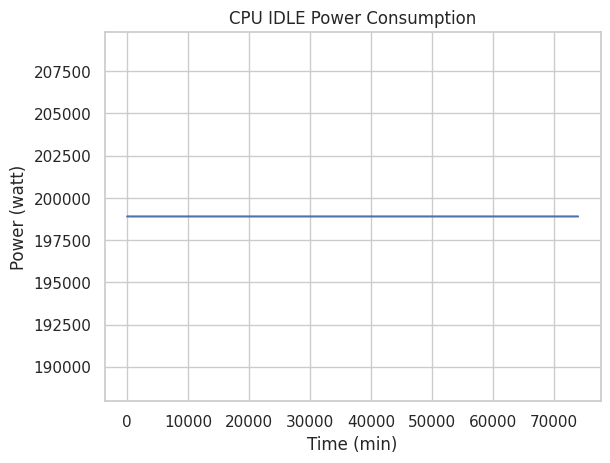

In [9]:
time = np.arange(len(idle_usage))
sns.set_theme(style='whitegrid')
plt.title('CPU IDLE Power Consumption')
plt.xlabel('Time (min)')
plt.ylabel('Power (watt)')
sns.lineplot(x=time, y=idle_usage)


In [36]:
ts = pl.DataFrame({ 'time': time, 'power': idle_usage })
ts

time,power
i64,f64
0,198900.0
1,198900.0
2,198900.0
3,198900.0
4,198900.0
…,…
73950,198900.0
73951,198900.0
73952,198900.0


In [37]:
ts.write_csv('../data/alibaba-2020/generated/cpu_idle_power_min.csv')